# eICU-CRD — Predizione del deterioramento clinico con NEWS-2 e Delta-NEWS
### Tesi Triennale in Ingegneria Biomedica

**Tesi:** *Progettazione di un modulo di interoperabilità per la sorveglianza automatizzata in terapia sub-intensiva*

**Domanda di ricerca:**
> È possibile progettare un modello di sorveglianza automatizzata che, a partire dai parametri
> vitali di routine sintetizzati nel NEWS-2 e nella sua evoluzione nel tempo (Delta-NEWS),
> predica il deterioramento clinico entro 24 ore, e che sia interoperabile, cioè applicabile
> con la stessa metodologia a basi dati cliniche eterogenee (MIMIC-IV, eICU-CRD, HiRID)?

**Interoperabilità:** i tre database usano schemi, codifiche e unità di misura diverse
(itemid in MIMIC-IV, nomi testuali in eICU-CRD, variableid in HiRID; temperature in °F e °C;
GCS verbale o totale). Ogni notebook traduce la propria sorgente nello stesso insieme comune di
20 variabili, con lo stesso endpoint e gli stessi modelli: è questo strato di armonizzazione che
rende il modello trasferibile da una base dati all'altra.

**Terapia sub-intensiva:** il modello è **pensato per** la sorveglianza automatizzata in terapia
sub-intensiva: il NEWS-2, su cui si basa, è nato proprio per il monitoraggio dei pazienti fuori dalla
terapia intensiva. Poiché non esistono database pubblici di terapia sub-intensiva con parametri vitali
ad alta frequenza, è stato **sviluppato e validato su** dati di terapia intensiva, il setting più vicino
disponibile. La validazione su dati di terapia sub-intensiva è lo sviluppo futuro naturale del lavoro.

**Differenze strutturali rispetto a MIMIC-IV — documentate per trasparenza:**

| Aspetto | MIMIC-IV | eICU-CRD |
|---|---|---|
| Unità di analisi | `subject_id` (paziente) | `patientunitstayid` (episodio ICU) |
| Tempo | `charttime` (timestamp) | `observationoffset` (minuti dall'ammissione) |
| GCS → AVPU | GCS verbale 1–5, soglia < 5 | GCS totale 3–15, soglia < 14 |
| Rumore | Basso | Alto → filtro artefatti temporali aggiuntivo |
| Vasopressori | `inputevents` (item ID) | `infusionDrug` (keyword matching) |
| Intubazione | `procedureevents` (item ID) | `treatment` (keyword matching) |
| Morte | `hospital_expire_flag` + `deathtime` durante la degenza ICU | `unitdischargestatus` = Expired, orario `unitdischargeoffset` |

**Ruolo nella tesi:** eICU-CRD è il **confronto secondario** rispetto a HiRID (riferimento) e MIMIC-IV
(confronto principale). È multicentrico: più ospedali, con abitudini di registrazione diverse.

**Pipeline:**
1. Caricamento parametri vitali da `vitalPeriodic`, `vitalAperiodic` e `nurseCharting` (campione casuale di 20.000 ricoveri)
2. Pulizia outlier assoluti + filtro artefatti temporali (separati)
3. Ricampionamento a 10 minuti
4. Imputazione valori mancanti
5. Calcolo NEWS-2 con AVPU standardizzato (GCS totale, soglia ≥ 14 = Alert)
6. Calcolo Delta-NEWS su finestra fissa di 6 ore
7. Endpoint composito: morte ICU + inizio vasopressori + intubazione (finestra 24 ore, solo insorgenza)
8. Split train/validation/test **per persona** (`uniquepid`)
9. Addestramento RF, LR, XGBoost
10. Scelta del modello sulla validazione (punteggio composito) e confronto con il NEWS-2 usato da solo
11. Valutazione: AUROC, AUPRC, Calibrazione, DCA, SHAP, bootstrap per paziente
12. Ricalibrazione isotonica e tempo di anticipo degli allarmi
13. Consensus dei tre modelli (ensemble) e confronto con il modello scelto

## FASE 1 — Preprocessing
## 1. Setup e Configurazione

In [1]:
import pandas as pd
import numpy as np
import os

CARTELLA_EICU   = "eicu-collaborative-research-database-2.0/"
CARTELLA_OUTPUT = "data_eicu/"
os.makedirs(CARTELLA_OUTPUT, exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Keyword vasopressori per endpoint composito
VASOPRESSORI_KW = ["norepinephrine", "epinephrine", "dopamine",
                   "vasopressin", "phenylephrine", "neosynephrine",
                   "noradrenaline", "adrenaline"]
LIBERO_TRATTAMENTO_MIN = 360   # 6 ore: un vasopressore o una registrazione di ventilazione contano come NUOVA insorgenza solo se non ce n'era una nelle 6 ore precedenti (stessa soglia usata in HiRID/MIMIC)

print("=" * 60)
print("FASE 1 — Preparazione dataset eICU-CRD")
print("=" * 60)


FASE 1 — Preparazione dataset eICU-CRD


## 2. Caricamento Dati (Passo 1.1)
L'unità di analisi delle righe è il **ricovero ICU** (`patientunitstayid`). Una stessa persona può avere più
ricoveri: per questo lo split (Passo 1.9) è fatto per persona (`uniquepid`), così i ricoveri della stessa persona
finiscono nello stesso insieme.

Si estrae un **campione casuale** di 20.000 ricoveri (seme fisso 42). Nella prima versione si prendevano i primi
20.000 del file, un campione non rappresentativo (pochissimi vasopressori).

La pressione sistolica arriva da due fonti: invasiva (`vitalPeriodic`, catetere arterioso) e non invasiva
(`vitalAperiodic`, bracciale). Senza la non invasiva mancherebbe proprio nei pazienti meno gravi.

In [2]:
print("\n[PASSO 1.1] Caricamento file CSV...")
vitali = pd.read_csv(
    CARTELLA_EICU + "vitalPeriodic.csv.gz", compression="gzip",
    usecols=["patientunitstayid", "observationoffset",
             "respiration", "sao2", "systemicsystolic", "heartrate", "temperature"]
)
print(f"  vitalPeriodic: {len(vitali):,} righe")

# Campionamento CASUALE (seed fisso, riproducibile) invece dei primi N ID incontrati nel file:
# .unique()[:20000] prendeva sempre gli stessi pazienti nell'ordine del file,
# rischiando un campione non rappresentativo (es. concentrato su pochi ospedali in eICU-CRD).
_rng = np.random.default_rng(42)
_id_unici = vitali["patientunitstayid"].unique()
pazienti_campione = _rng.choice(_id_unici, size=min(20000, len(_id_unici)), replace=False)
vitali = vitali[vitali["patientunitstayid"].isin(pazienti_campione)]
print(f"  Campione: {len(vitali):,} righe, {len(pazienti_campione):,} ricoveri")

nursing = pd.read_csv(
    CARTELLA_EICU + "nurseCharting.csv.gz", compression="gzip",
    usecols=["patientunitstayid", "nursingchartoffset",
             "nursingchartcelltypevalname", "nursingchartvalue"]
)
nursing = nursing[nursing["patientunitstayid"].isin(pazienti_campione)]
print(f"  nurseCharting: {len(nursing):,} righe")

paziente = pd.read_csv(
    CARTELLA_EICU + "patient.csv.gz", compression="gzip",
    usecols=["patientunitstayid", "uniquepid",
             "unitdischargestatus", "hospitaldischargestatus",
             "unitdischargeoffset"]   # MODIFICA 1a: minuti dall'ammissione alla dimissione dall'ICU
)
paziente = paziente[paziente["patientunitstayid"].isin(pazienti_campione)]
print(f"  patient: {len(paziente):,} righe")

# MODIFICA 1b: pressione sistolica NON invasiva (bracciale). vitalPeriodic contiene solo quella
# invasiva (catetere arterioso), presente soprattutto nei pazienti più gravi.
aperiodici = pd.read_csv(
    CARTELLA_EICU + "vitalAperiodic.csv.gz", compression="gzip",
    usecols=["patientunitstayid", "observationoffset", "noninvasivesystolic"]
)
aperiodici = aperiodici[aperiodici["patientunitstayid"].isin(pazienti_campione)]   # solo il campione
aperiodici = aperiodici.dropna(subset=["noninvasivesystolic"])                     # solo righe con un valore
print(f"  vitalAperiodic (pressione non invasiva): {len(aperiodici):,} righe")


[PASSO 1.1] Caricamento file CSV...


  vitalPeriodic: 146,671,642 righe


  Campione: 15,193,800 righe, 20,000 ricoveri


  nurseCharting: 15,533,323 righe


  patient: 20,000 righe


  vitalAperiodic (pressione non invasiva): 2,274,563 righe


## 3. Estrazione GCS, O2 Supplementare e Temperatura da nurseCharting (Passo 1.2)
Il GCS totale (3–15) è usato come proxy AVPU con soglia ≥ 14 = Alert (documentata nel passo 1.6).

L'**ossigeno supplementare** si ricava dai nomi esatti di due voci:
- `O2 Admin Device`: il dispositivo; "RA"/"room air"/"none" = aria ambiente (0), altrimenti 1;
- `O2 L/%`: flusso (L/min) o FiO2 (%); > 0 = ossigeno.

Nella prima versione la parola chiave "O2" trovava anche "O2 Saturation", cioè la saturazione, non l'ossigenoterapia.

Anche la **temperatura** si prende da `nurseCharting` (in `vitalPeriodic` è scarsa); i valori in °F sono convertiti in °C.

In [3]:
print("\n[PASSO 1.2] Estrazione GCS e O2 supplementare...")

coscienza = nursing[
    nursing["nursingchartcelltypevalname"].str.contains("GCS Total", case=False, na=False)
].copy()
coscienza = coscienza.rename(columns={
    "nursingchartoffset": "observationoffset",
    "nursingchartvalue": "coscienza_gcs"
})
coscienza["coscienza_gcs"] = pd.to_numeric(coscienza["coscienza_gcs"], errors="coerce")
coscienza = coscienza[["patientunitstayid", "observationoffset", "coscienza_gcs"]]
print(f"  Righe GCS trovate: {len(coscienza):,}")

# Ossigeno supplementare: si usano i NOMI ESATTI delle due voci di ossigeno (la parola chiave "O2"
# trovava anche "O2 Saturation", cioe' la saturazione, non l'ossigenoterapia).
#  - "O2 Admin Device": dispositivo (ventilator, nasal cannula, ...). "RA"/"room air" = aria ambiente (0).
#  - "O2 L/%": flusso (L/min) o FiO2 (%): > 0 = ossigeno.
_nome = nursing["nursingchartcelltypevalname"]
o2_disp = nursing[_nome == "O2 Admin Device"].copy()
o2_disp["ossigeno_supplementare"] = (~o2_disp["nursingchartvalue"].astype(str).str.strip().str.lower()
                                      .isin({"ra", "room air", "none"})).astype(int)
o2_flusso = nursing[_nome == "O2 L/%"].copy()
o2_flusso["ossigeno_supplementare"] = (pd.to_numeric(o2_flusso["nursingchartvalue"], errors="coerce") > 0).astype(int)
o2_suppl = pd.concat([o2_disp, o2_flusso]).rename(columns={"nursingchartoffset": "observationoffset"})
o2_suppl = (o2_suppl.groupby(["patientunitstayid", "observationoffset"], as_index=False)
            ["ossigeno_supplementare"].max())
print(f"  Righe O2 trovate: {len(o2_suppl):,}")

# NUOVO: temperatura da nurseCharting. In vitalPeriodic è scarsa: prima quasi tutte le righe
# finivano riempite con la mediana (quartili tutti 37,22).
_nomi_temp = ["Temperature (C)", "Temperature (F)"]
temp_inf = nursing[nursing["nursingchartcelltypevalname"].isin(_nomi_temp)].copy()
temp_inf["temperatura"] = pd.to_numeric(temp_inf["nursingchartvalue"], errors="coerce")   # testo -> numero
_in_f = temp_inf["nursingchartcelltypevalname"] == "Temperature (F)"
temp_inf.loc[_in_f, "temperatura"] = (temp_inf.loc[_in_f, "temperatura"] - 32) * 5 / 9   # °C = (°F − 32) × 5/9
temp_inf = (temp_inf.rename(columns={"nursingchartoffset": "observationoffset"})
            [["patientunitstayid", "observationoffset", "temperatura"]]
            .dropna(subset=["temperatura"]))
print(f"  Righe temperatura trovate: {len(temp_inf):,} "
      f"(di cui convertite da Fahrenheit: {int(_in_f.sum()):,})")

if len(temp_inf) == 0:   # controllo: se i nomi delle voci fossero diversi, li stampa per correggerli
    print("  ATTENZIONE: nessuna temperatura trovata. Voci disponibili che contengono 'temp':")
    print(nursing.loc[nursing["nursingchartcelltypevalname"].str.contains("temp", case=False, na=False),
                      "nursingchartcelltypevalname"].value_counts().head(10))


[PASSO 1.2] Estrazione GCS e O2 supplementare...


  Righe GCS trovate: 334,439


  Righe O2 trovate: 312,404


  Righe temperatura trovate: 1,269,998 (di cui convertite da Fahrenheit: 634,925)


## 4. Integrazione Temporale (Passo 1.3)

In [4]:
print("\n[PASSO 1.3] Unione parametri...")

vitali = vitali.rename(columns={
    "respiration": "freq_respiratoria", "sao2": "spo2",
    "systemicsystolic": "pressione_sistolica", "heartrate": "freq_cardiaca",
    "temperature": "temperatura"
})
aperiodici = aperiodici.rename(columns={"noninvasivesystolic": "pressione_sistolica"})   # stessa colonna della invasiva, come in HiRID e MIMIC-IV

# CORRETTO: le fonti si mettono una sotto l'altra (concat) invece di unirle sul minuto esatto.
# Prima il GCS restava solo se cadeva nello stesso minuto di una riga di vitalPeriodic.
# Righe diverse nello stesso blocco di 10 minuti vengono combinate dal ricampionamento.
df = pd.concat([vitali, aperiodici, temp_inf, coscienza], ignore_index=True)

print(f"  GCS presenti nel dataset: {df['coscienza_gcs'].notna().sum():,} (trovati in nurseCharting: {len(coscienza):,})")
print(f"  Pressioni presenti: {df['pressione_sistolica'].notna().sum():,}")
print(f"  Temperature presenti: {df['temperatura'].notna().sum():,}")

# Ossigeno: invariato. Vale l'ULTIMA registrazione dello stesso ricovero entro 4 ore (240 minuti);
# la registrazione "aria ambiente" azzera lo stato. Senza registrazioni recenti: 0.
df = df.sort_values("observationoffset")
o2_suppl = o2_suppl.sort_values("observationoffset")
df = pd.merge_asof(df, o2_suppl, on="observationoffset", by="patientunitstayid",
                   direction="backward", tolerance=240)
df["ossigeno_supplementare"] = df["ossigeno_supplementare"].fillna(0)
print(f"  Dataset unificato: {len(df):,} righe, {len(df.columns)} colonne")
print(f"  Ricoveri unici: {df['patientunitstayid'].nunique():,}")


[PASSO 1.3] Unione parametri...


  GCS presenti nel dataset: 325,846 (trovati in nurseCharting: 334,439)
  Pressioni presenti: 5,207,269
  Temperature presenti: 2,579,866


  Dataset unificato: 19,072,800 righe, 9 colonne
  Ricoveri unici: 20,000


## 5. Pulizia Outlier e Filtro Artefatti Temporali (Passo 1.4)

La pulizia avviene in **due fasi separate**:
1. **Outlier assoluti** — valori fuori dai range fisiologici → sostituiti con NaN
2. **Artefatti temporali** — salti fisiologicamente impossibili in tempi brevi
   (es. FC > 50 bpm in ≤ 10 min) — tipici di eICU-CRD per rumore da movimento

Le due fasi sono deliberatamente separate per chiarezza metodologica.


In [5]:
print("\n[PASSO 1.4a] Pulizia outlier assoluti...")

filtri = {
    "freq_respiratoria":  (4,   60),
    "spo2":               (50,  100),
    "pressione_sistolica":(40,  300),
    "freq_cardiaca":      (10,  300),
    "temperatura":        (25,  45),
    "coscienza_gcs":      (3,   15),  # GCS totale eICU-CRD
}
for colonna, (minimo, massimo) in filtri.items():
    if colonna in df.columns:
        n_prima = df[colonna].notna().sum()
        df.loc[(df[colonna] < minimo) | (df[colonna] > massimo), colonna] = np.nan
        n_rimossi = n_prima - df[colonna].notna().sum()
        if n_rimossi > 0:
            print(f"  {colonna}: rimossi {n_rimossi:,} valori fuori range")

# ── Filtro artefatti temporali (separato dal loop precedente) ────────────────
print("\n[PASSO 1.4b] Rimozione artefatti temporali (salti impossibili)...")
df = df.sort_values(["patientunitstayid", "observationoffset"])
df["delta_tempo_min"] = df.groupby("patientunitstayid")["observationoffset"].diff()

delta_fc = df.groupby("patientunitstayid")["freq_cardiaca"].diff().abs()
mask_fc  = (delta_fc > 50) & (df["delta_tempo_min"] <= 10)
df.loc[mask_fc, "freq_cardiaca"] = np.nan

delta_pa = df.groupby("patientunitstayid")["pressione_sistolica"].diff().abs()
mask_pa  = (delta_pa > 60) & (df["delta_tempo_min"] <= 10)
df.loc[mask_pa, "pressione_sistolica"] = np.nan

print(f"  Artefatti FC rimossi : {mask_fc.sum():,}")
print(f"  Artefatti PA rimossi : {mask_pa.sum():,}")
df = df.drop(columns=["delta_tempo_min"])



[PASSO 1.4a] Pulizia outlier assoluti...


  freq_respiratoria: rimossi 168,582 valori fuori range


  spo2: rimossi 5,814 valori fuori range


  pressione_sistolica: rimossi 4,207 valori fuori range


  freq_cardiaca: rimossi 3,230 valori fuori range


  temperatura: rimossi 35,204 valori fuori range



[PASSO 1.4b] Rimozione artefatti temporali (salti impossibili)...


  Artefatti FC rimossi : 3,226
  Artefatti PA rimossi : 11,801


## 6. Ricampionamento a 10 Minuti (Passo 1.4c)

eICU-CRD registra parametri vitali con alta frequenza. Variazioni in pochi minuti
riflettono rumore strumentale, non cambiamenti clinici reali.

Il ricampionamento risolve due cose:
Il primo problema è il rumore — invece di tenere ogni misurazione al minuto, prendi la media su finestre da 10 minuti. Le oscillazioni casuali del sensore si smorzano e rimane il segnale clinico reale.
Il secondo problema riguarda il Delta-NEWS — se le misurazioni sono al minuto, il Delta-NEWS calcolato su 6 ore confronta valori molto rumorosi. Su dati ricampionati a 10 minuti il Delta-NEWS è molto più stabile e clinicamente interpretabile.
Si aggrega ogni 10 minuti calcolando la **media** dei parametri vitali,
coerentemente con le linee guida NEWS-2 (RCP 2017) che raccomandano
una rivalutazione ogni 10–15 minuti per pazienti a rischio.

In [6]:
print("\n[PASSO 1.4c] Ricampionamento a 10 minuti...")

righe_prima = len(df)

# Converti offset in timedelta per resample basato sul tempo
df["offset_td"] = pd.to_timedelta(df["observationoffset"], unit="min")
df = df.set_index("offset_td")

cols_mancanti_flag = [c for c in df.columns if c.endswith("_mancante")]

agg_dict = {
    "freq_respiratoria":   "mean",
    "spo2":                "mean",
    "pressione_sistolica": "mean",
    "freq_cardiaca":       "mean",
    "temperatura":         "mean",
    "ossigeno_supplementare": "max",
    "coscienza_gcs":       "mean",
}

df = (
    df.groupby("patientunitstayid")
      .resample("10min")
      .agg(agg_dict)
      .dropna(how="all")
      .reset_index()
)

# Ripristina observationoffset in minuti
df["observationoffset"] = df["offset_td"].dt.total_seconds() / 60
df = df.drop(columns=["offset_td"])

print(f"  Righe prima: {righe_prima:,}")
print(f"  Righe dopo : {len(df):,}  (riduzione {(1 - len(df)/righe_prima)*100:.0f}%)")



[PASSO 1.4c] Ricampionamento a 10 minuti...


  Righe prima: 19,072,800
  Righe dopo : 7,868,881  (riduzione 59%)


## 7. Imputazione Valori Mancanti (Passo 1.5)

1. **Flag mancanza** — creato prima dell'imputazione: il modello apprende anche dall'assenza del dato
2. **Riporto dell'ultimo valore vero fino a 4 ore** (forward fill basato sul tempo, per tutti e sei i parametri; stessa finestra dell'ossigeno). Il tempo trascorso dall'ultima misura serve solo a questo limite, non è una feature del modello
3. **Valori fisiologici fissi** per ciò che resta (i buchi iniziali del ricovero e le misure più vecchie di 4 ore), identici a HiRID e MIMIC-IV

In [7]:
print("\n[PASSO 1.5] Gestione valori mancanti...")
df = df.sort_values(["patientunitstayid", "observationoffset"])
parametri = ["freq_respiratoria", "spo2", "pressione_sistolica",
             "freq_cardiaca", "temperatura", "coscienza_gcs"]

# Tempo trascorso dall'ultima misurazione valida (in minuti).
# Non è più una feature del modello, ma serve qui sotto per il limite di 4 ore.
for col in parametri:
    df[f"{col}_last_time"] = df.loc[df[col].notna(), "observationoffset"]
    df[f"{col}_last_time"] = df.groupby("patientunitstayid")[f"{col}_last_time"].ffill()
    df[f"{col}_tempo_trascorso_min"] = (
        df["observationoffset"] - df[f"{col}_last_time"]
    ).fillna(0)
    df = df.drop(columns=[f"{col}_last_time"])

# Flag mancanza PRIMA dell'imputazione
for col in parametri:
    df[f"{col}_mancante"] = df[col].isna().astype(int)

# CORRETTO: forward-fill basato sul TEMPO, non sul numero di righe.
# Prima: limit=4 righe = 40 minuti, troppo poco per parametri misurati ogni qualche ora
# (la temperatura restava 37,0 nella maggior parte delle righe).
# Ora: si porta avanti l'ultimo valore vero se ha al massimo 4 ore, la stessa finestra
# usata per l'ossigeno supplementare. Oltre le 4 ore il dato torna mancante e riceve
# il valore fisiologico fisso qui sotto.
LIMITE_FFILL_MIN = 240   # 4 ore
for col in parametri:   # tutti e sei i parametri (entro 4 ore), come in HiRID
    riempito = df.groupby("patientunitstayid")[col].ffill()                  # porta avanti l'ultimo valore vero
    troppo_vecchio = df[f"{col}_tempo_trascorso_min"] > LIMITE_FFILL_MIN     # quel valore ha più di 4 ore?
    df[col] = riempito.where(~troppo_vecchio)                                # se sì, torna mancante
# L'ossigeno non è in questa lista: ha già la sua persistenza di 4 ore (Passo 1.3)
# e non ha valori mancanti, quindi il forward-fill su di lui non faceva nulla.

print("  Blocchi con valore vero, prima dei valori fissi:")
for col in parametri:
    print(f"    {col:22s} {100 * df[col].notna().mean():5.1f}%")
    
# Valori fisiologici fissi, identici a HiRID e MIMIC-IV
valori_fisiologici = {
    "freq_respiratoria": 16, "spo2": 97, "pressione_sistolica": 120,
    "freq_cardiaca": 70, "temperatura": 37.0, "coscienza_gcs": 15,
}
for col in parametri:
    df[col] = df[col].fillna(valori_fisiologici[col])

n_nan = df[parametri].isna().sum().sum()
print(f"  Valori mancanti residui: {n_nan} [deve essere 0]")


[PASSO 1.5] Gestione valori mancanti...


  Blocchi con valore vero, prima dei valori fissi:
    freq_respiratoria       86.5%
    spo2                    93.8%
    pressione_sistolica     96.0%
    freq_cardiaca           97.0%
    temperatura             80.0%
    coscienza_gcs           50.6%


  Valori mancanti residui: 0 [deve essere 0]


## 8. Calcolo NEWS-2 con AVPU Standardizzato (Passo 1.6)

**Standardizzazione AVPU — eICU-CRD:**
eICU-CRD fornisce il GCS totale (scala 3–15). La mappatura verso AVPU è:
- GCS totale **≥ 14** → Alert (A) → **0 punti NEWS-2**
- GCS totale **≤ 13** → qualsiasi compromissione (V/P/U) → **3 punti NEWS-2**

Questa soglia è equivalente a MIMIC-IV (GCS verbale < 5),
consentendo il confronto diretto tra i tre database.
Fonte: mappatura GCS→AVPU da Gill et al. (2004); RCP NEWS-2 (2017).

In [8]:
print("\n[PASSO 1.6] Calcolo NEWS-2 con AVPU standardizzato...")

def calcola_news2(row):
    """
    NEWS-2 secondo Royal College of Physicians (2017).
    Punteggio 0-20 (più alto = paziente più grave).
    AVPU proxy via GCS totale eICU-CRD (3-15):
      - GCS >= 14 = Alert (0 pt)
      - GCS <= 13 = compromissione (3 pt)
    """
    score = 0

    fr = row["freq_respiratoria"]
    if   fr <= 8:  score += 3
    elif fr <= 11: score += 1
    elif fr <= 20: score += 0
    elif fr <= 24: score += 2
    else:          score += 3

    spo2 = row["spo2"]
    if   spo2 <= 91: score += 3
    elif spo2 <= 93: score += 2
    elif spo2 <= 95: score += 1

    if row["ossigeno_supplementare"] > 0:
        score += 2

    pa = row["pressione_sistolica"]
    if   pa <= 90:  score += 3
    elif pa <= 100: score += 2
    elif pa <= 110: score += 1
    elif pa <= 219: score += 0
    else:           score += 3

    fc = row["freq_cardiaca"]
    if   fc <= 40:  score += 3
    elif fc <= 50:  score += 1
    elif fc <= 90:  score += 0
    elif fc <= 110: score += 1
    elif fc <= 130: score += 2
    else:           score += 3

    # Livello di coscienza — proxy AVPU tramite GCS totale (eICU-CRD)
    # GCS totale >= 14 = Alert -> 0 pt
    # GCS totale <= 13 = compromissione -> 3 pt  (equivalente a MIMIC: GCS verbale < 5)
    gcs = row["coscienza_gcs"]
    if gcs < 14:
        score += 3

    temp = row["temperatura"]
    if   temp <= 35.0: score += 3
    elif temp <= 36.0: score += 1
    elif temp <= 38.0: score += 0
    elif temp <= 39.0: score += 1
    else:              score += 2

    return score

df["news2"] = df.apply(calcola_news2, axis=1)
print(f"  NEWS-2 calcolato. Media: {df['news2'].mean():.2f} | Max: {df['news2'].max()}")



[PASSO 1.6] Calcolo NEWS-2 con AVPU standardizzato...


  NEWS-2 calcolato. Media: 3.58 | Max: 20


## 9. Delta-NEWS su Finestra Fissa di 6 Ore (Passo 1.7)

Il **Delta-NEWS** affianca il NEWS-2 istantaneo: ne misura l'evoluzione nel tempo (la traiettoria del paziente).

**Nota implementativa — eICU vs MIMIC:**
In MIMIC-IV si usa un DatetimeIndex con `rolling("360min")`.
In eICU-CRD il tempo è `observationoffset` (minuti numerici):
si converte in timedelta per applicare lo stesso rolling temporale.

**Formula:**
```
delta_news_6h(t) = NEWS-2(t) − NEWS-2(più vecchio nella finestra [t−6h, t])
```
Valore positivo → peggioramento; negativo → miglioramento.


In [9]:
print("\n[PASSO 1.7] Calcolo Delta-NEWS e feature temporali su finestra di 6 ore...")

df = df.sort_values(["patientunitstayid", "observationoffset"])

# Converti offset in timedelta per usare rolling basato sul tempo reale
df["offset_td"] = pd.to_timedelta(df["observationoffset"], unit="min")
df = df.set_index("offset_td")

def features_temporali_eicu(gruppo):
    gruppo = gruppo.sort_index()
    rolling = gruppo["news2"].rolling("360min", min_periods=1)

    # Feature rolling window (statistiche delle ultime 6 ore)
    gruppo["news2_max_6h"]   = rolling.max()
    gruppo["news2_min_6h"]   = rolling.min()
    gruppo["news2_media_6h"] = rolling.mean()
    gruppo["news2_std_6h"]   = rolling.std().fillna(0)

    # Delta-NEWS istantaneo (rispetto alla misurazione precedente)
    gruppo["delta_news"] = gruppo["news2"].diff().fillna(0)

    # ── Delta-NEWS su finestra FISSA di 6 ore ─────────────────────────────
    # Per ogni istante t, prende il NEWS più vecchio nella finestra [t-360min, t]
    # e calcola la differenza col valore attuale.
    news_6h_fa = (
        gruppo["news2"]
        .rolling("360min", min_periods=2)
        .apply(lambda x: x.iloc[0], raw=False)
    )
    gruppo["delta_news_6h"] = (gruppo["news2"] - news_6h_fa).fillna(0)

    # Conta parametri mancanti per riga
    cols_m = [c for c in gruppo.columns if c.endswith("_mancante")]
    gruppo["n_parametri_mancanti"] = gruppo[cols_m].sum(axis=1)

    return gruppo

df = (
    df.groupby("patientunitstayid", group_keys=True)
      .apply(features_temporali_eicu, include_groups=False)
      .reset_index()
)

# Ripristina observationoffset in minuti
df["observationoffset"] = df["offset_td"].dt.total_seconds() / 60
df = df.drop(columns=["offset_td"])

print("  Feature temporali calcolate:")
print(f"    delta_news (istantaneo) — media: {df['delta_news'].mean():.3f}")
print(f"    delta_news_6h (6h)      — media: {df['delta_news_6h'].mean():.3f}")



[PASSO 1.7] Calcolo Delta-NEWS e feature temporali su finestra di 6 ore...


  Feature temporali calcolate:
    delta_news (istantaneo) — media: 0.002
    delta_news_6h (6h)      — media: 0.087


## 10. Endpoint Composito — Finestra 24 Ore (Passo 1.8)
Tre fonti di evento. Vasopressori e ventilazione contano come **insorgenza**, non come presenza continua:
- **Morte**: solo i decessi in terapia intensiva (`unitdischargestatus` = Expired), con orario la dimissione
  dall'ICU (`unitdischargeoffset`), che per un deceduto coincide con il decesso. Nella prima versione contavano
  anche i decessi in ospedale dopo la dimissione dall'ICU: le ultime 24 ore in ICU di un paziente dimesso vivo
  risultavano "deterioramento".
- `infusionDrug` ha una riga per ogni registrazione della stessa infusione (verificato: 1.002.354 righe,
  quasi 40 per ricovero in media, il 94,5% con un'altra riga nelle 6 ore precedenti) — teniamo solo la
  prima riga dopo almeno `LIBERO_TRATTAMENTO_MIN` minuti senza vasopressori.
- `treatment` per la ventilazione ha lo stesso problema (verificato: 190.914 righe, 4,5 per ricovero) e in
  più la parola chiave "endotracheal" catturava anche **"endotracheal tube removal"**, cioè l'estubazione
  veniva contata come una nuova intubazione — corretto escludendo le voci di rimozione/interruzione e
  applicando la stessa regola dell'insorgenza.


In [10]:
print("\n[PASSO 1.8] Costruzione endpoint composito (24 ore = 1440 minuti)...")

FINESTRA_MIN = 1440

# A. Morte in terapia intensiva 
# Prima contavano anche i decessi in ospedale DOPO la dimissione dall'ICU, datati alla fine della
# degenza ICU: le ultime 24 ore in ICU di un paziente dimesso vivo risultavano "deterioramento".
# Ora: solo i decessi in ICU (unitdischargestatus), come in MIMIC-IV. L'istante è la dimissione
# dall'ICU (unitdischargeoffset), che per un paziente deceduto in ICU corrisponde al decesso:
# più preciso dell'ultima misura registrata usata prima.
morti = paziente[
    paziente["unitdischargestatus"].str.lower().str.contains("expired|dead", na=False)
][["patientunitstayid", "unitdischargeoffset"]].copy()
morti = morti.rename(columns={"unitdischargeoffset": "evento_offset"})
morti["tipo_evento"] = "morte_icu"
print(f"  Decessi in ICU     : {len(morti):,}")

# B. Vasopressori
try:
    infusion = pd.read_csv(
        CARTELLA_EICU + "infusionDrug.csv.gz", compression="gzip",
        usecols=["patientunitstayid", "infusionoffset", "drugname"]
    )
    infusion = infusion[infusion["patientunitstayid"].isin(pazienti_campione)]
    pattern_vaso = "|".join(VASOPRESSORI_KW)
    vasopressori = infusion[
        infusion["drugname"].str.lower().str.contains(pattern_vaso, na=False)
    ][["patientunitstayid", "infusionoffset"]].copy()
    vasopressori = vasopressori.rename(columns={"infusionoffset": "evento_offset"})
    # Insorgenza: infusionDrug ha una riga per ogni registrazione della stessa infusione (dose invariata
    # o meno); contarle tutte farebbe risultare "deteriorato" un paziente per l'intera durata della terapia.
    # Teniamo solo la prima riga di ogni ricovero e quelle dopo almeno LIBERO_TRATTAMENTO_MIN minuti senza
    # vasopressori (qualunque farmaco) per lo stesso ricovero.
    vasopressori = vasopressori.sort_values(["patientunitstayid", "evento_offset"])
    _min_dal_precedente = vasopressori["evento_offset"] - vasopressori.groupby("patientunitstayid")["evento_offset"].shift(1)
    vasopressori = vasopressori[_min_dal_precedente.isna() | (_min_dal_precedente > LIBERO_TRATTAMENTO_MIN)].copy()
    vasopressori["tipo_evento"] = "vasopressore"
    print(f"  Vasopressori       : {len(vasopressori):,}")
except Exception as e:
    print(f"  [ATTENZIONE] infusionDrug non disponibile: {e}")
    vasopressori = pd.DataFrame(columns=["patientunitstayid", "evento_offset", "tipo_evento"])

# C. Intubazione
try:
    treatment = pd.read_csv(
        CARTELLA_EICU + "treatment.csv.gz", compression="gzip",
        usecols=["patientunitstayid", "treatmentoffset", "treatmentstring"]
    )
    treatment = treatment[treatment["patientunitstayid"].isin(pazienti_campione)]
    _testo = treatment["treatmentstring"].str.lower()
    # "endotracheal" cattura anche "endotracheal tube removal" (estubazione): la escludiamo esplicitamente,
    # altrimenti un'estubazione verrebbe contata come una nuova intubazione.
    intubazioni = treatment[
        _testo.str.contains("intubat|mechanical vent|endotracheal", na=False)
        & ~_testo.str.contains("removal|discontinu", na=False)
    ][["patientunitstayid", "treatmentoffset"]].copy()
    intubazioni = intubazioni.rename(columns={"treatmentoffset": "evento_offset"})
    # Insorgenza: "mechanical ventilation" è una voce di documentazione ripetuta durante la ventilazione,
    # non un evento singolo di inizio — stessa logica dei vasopressori, stessa soglia.
    intubazioni = intubazioni.sort_values(["patientunitstayid", "evento_offset"])
    _min_dal_precedente_i = intubazioni["evento_offset"] - intubazioni.groupby("patientunitstayid")["evento_offset"].shift(1)
    intubazioni = intubazioni[_min_dal_precedente_i.isna() | (_min_dal_precedente_i > LIBERO_TRATTAMENTO_MIN)].copy()
    intubazioni["tipo_evento"] = "intubazione"
    print(f"  Intubazioni        : {len(intubazioni):,}")
except Exception as e:
    print(f"  [ATTENZIONE] treatment non disponibile: {e}")
    intubazioni = pd.DataFrame(columns=["patientunitstayid", "evento_offset", "tipo_evento"])

tutti_eventi = pd.concat([morti, vasopressori, intubazioni], ignore_index=True)

# Assegnazione etichetta
merged = df[["patientunitstayid", "observationoffset"]].merge(
    tutti_eventi, on="patientunitstayid", how="left"
)
merged["min_al_evento"] = merged["evento_offset"] - merged["observationoffset"]
merged["evento_24h"] = (merged["min_al_evento"] > 0) & (merged["min_al_evento"] <= FINESTRA_MIN)

etichette = (
    merged.groupby(["patientunitstayid", "observationoffset"])["evento_24h"]
    .any().astype(int).reset_index()
    .rename(columns={"evento_24h": "deterioramento"})
)
df = df.merge(etichette, on=["patientunitstayid", "observationoffset"], how="left")
df["deterioramento"] = df["deterioramento"].fillna(0).astype(int)

tasso = df["deterioramento"].mean() * 100
print(f"\n  Tasso di deterioramento: {tasso:.1f}%")
if tasso < 5:
    print("  ⚠️  Dataset molto sbilanciato — class_weight='balanced' è essenziale.")



[PASSO 1.8] Costruzione endpoint composito (24 ore = 1440 minuti)...
  Decessi in ICU     : 1,119


  Vasopressori       : 5,676


  Intubazioni        : 11,300



  Tasso di deterioramento: 16.0%


Nota: con l'endpoint a insorgenza i conteggi dei tre eventi separati cambiano rispetto alle versioni
precedenti del notebook (basate sul conteggio grezzo). Un ricovero può comunque comparire in più fonti
contemporaneamente (es. paziente già intubato che inizia anche un vasopressore): l'endpoint composito
conta il ricovero una volta sola, tramite `.any()`.

In [11]:
print(f"Decessi   : {len(morti):,}")
print(f"Vasopressori: {len(vasopressori):,}")
print(f"Intubazioni : {len(intubazioni):,}")
print(f"Totale eventi unici: {tutti_eventi['patientunitstayid'].nunique():,}")

Decessi   : 1,119
Vasopressori: 5,676
Intubazioni : 11,300
Totale eventi unici: 5,744


## 11. Split Train / Validation / Test per Persona (Passo 1.9)

Lo split avviene per **persona** (`uniquepid`): tutti i ricoveri della stessa persona finiscono
nello stesso insieme, così nessuno compare sia in training sia in test.
Proporzione: 60% train — 20% validation — 20% test.


In [12]:
from sklearn.model_selection import train_test_split

print("\n[PASSO 1.9] Split train/validation/test per persona (uniquepid)...")

# Feature set — stesse 20 variabili armonizzate in tutti e tre i database
FEATURES = [
    # Parametri vitali correnti
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura", "ossigeno_supplementare",
    # Score clinico
    "news2",
    # Feature temporali rolling 6h
    "news2_max_6h", "news2_min_6h", "news2_media_6h", "news2_std_6h",
    # Delta-NEWS — evoluzione del NEWS-2 nel tempo
    "delta_news",
    "delta_news_6h",       # variazione su finestra fissa 6h
    # Qualità del dato
    "n_parametri_mancanti",
    # Flag mancanza per parametro
    "freq_respiratoria_mancante", "spo2_mancante",
    "pressione_sistolica_mancante", "freq_cardiaca_mancante",
    "temperatura_mancante", "coscienza_gcs_mancante",
]

df_model = df[FEATURES + ["deterioramento", "patientunitstayid"]].dropna(subset=["deterioramento"])

# CORRETTO: split per PERSONA (uniquepid), non per ricovero. Una persona con più ricoveri
# finisce tutta nello stesso insieme: non può essere sia in training sia in test.
mappa_persona = paziente.set_index("patientunitstayid")["uniquepid"]
df_model["uniquepid"] = df_model["patientunitstayid"].map(mappa_persona)

persone_uniche = df_model["uniquepid"].unique()
train_ids, temp_ids = train_test_split(persone_uniche, test_size=0.40, random_state=42)
val_ids,   test_ids = train_test_split(temp_ids,       test_size=0.50, random_state=42)

df_train = df_model[df_model["uniquepid"].isin(train_ids)]
df_val   = df_model[df_model["uniquepid"].isin(val_ids)]
df_test  = df_model[df_model["uniquepid"].isin(test_ids)]

X_train = df_train[FEATURES]; y_train = df_train["deterioramento"]
X_val   = df_val[FEATURES];   y_val   = df_val["deterioramento"]
X_test  = df_test[FEATURES];  y_test  = df_test["deterioramento"]

overlap = len(set(train_ids) & set(test_ids))
print(f"  Train : {len(X_train):,} righe | {len(train_ids):,} persone | {df_train['patientunitstayid'].nunique():,} ricoveri")
print(f"  Val   : {len(X_val):,} righe | {len(val_ids):,} persone | {df_val['patientunitstayid'].nunique():,} ricoveri")
print(f"  Test  : {len(X_test):,} righe | {len(test_ids):,} persone | {df_test['patientunitstayid'].nunique():,} ricoveri")
print(f"  Persone in comune train/test: {overlap} [deve essere 0]")


[PASSO 1.9] Split train/validation/test per persona (uniquepid)...


  Train : 4,751,338 righe | 11,427 persone | 12,035 ricoveri
  Val   : 1,516,628 righe | 3,809 persone | 3,990 ricoveri
  Test  : 1,600,915 righe | 3,810 persone | 3,975 ricoveri
  Persone in comune train/test: 0 [deve essere 0]


## 12. Diagnostica del Dataset 
Verifica visiva che il preprocessing sia andato correttamente prima di addestrare i modelli.


In [13]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

print("=" * 65)
print("  DIAGNOSTICA DEL DATASET — eICU-CRD")
print("=" * 65)

print(f"\n[1] DIMENSIONI")
print(f"    Righe totali    : {len(df):,}")
print(f"    Ricoveri unici  : {df['patientunitstayid'].nunique():,}")

print(f"\n[2] PRIME 5 RIGHE")
print(df[["patientunitstayid", "observationoffset",
          "freq_respiratoria", "spo2", "freq_cardiaca",
          "news2", "delta_news_6h", "deterioramento"]].head(5).to_string(index=False))

print(f"\n[3] STATISTICHE DESCRITTIVE")
cols_v = ["freq_respiratoria","spo2","pressione_sistolica","freq_cardiaca","temperatura"]
print(df[cols_v].describe().round(2).to_string())

nan_c = df[FEATURES].isna().sum()
print(f"\n[4] VALORI MANCANTI: {'✓ Nessuno' if nan_c.sum()==0 else str(nan_c[nan_c>0])}")

n_tot = len(df); n_det = df["deterioramento"].sum(); n_stab = n_tot - n_det
tasso = n_det/n_tot*100
print(f"\n[5] ENDPOINT: {n_stab:,} stabili ({100-tasso:.1f}%) | {n_det:,} deteriorati ({tasso:.1f}%)")
print(f"    Split: {'✓ nessun overlap' if overlap==0 else '✗ ERRORE overlap!'}")

# Grafici
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

ax1 = fig.add_subplot(gs[0,0])
df["news2"].hist(bins=20, ax=ax1, color="#4C72B0", edgecolor="white")
ax1.axvline(5, color="orange", linestyle="--", linewidth=1.5, label="RCP ≥5")
ax1.axvline(7, color="red",    linestyle="--", linewidth=1.5, label="RCP ≥7")
ax1.set_title("Distribuzione NEWS-2"); ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[0,1])
df["delta_news_6h"].clip(-6,6).hist(bins=25, ax=ax2, color="#55A868", edgecolor="white")
ax2.axvline(0, color="black", linewidth=1)
ax2.set_title("Delta-NEWS 6h")

ax3 = fig.add_subplot(gs[0,2])
bars = ax3.bar(["Stabile","Deterioramento"], [n_stab, n_det],
               color=["#4C72B0","#C44E52"], edgecolor="white", width=0.5)
for b,v in zip(bars,[n_stab,n_det]):
    etichetta = f"{v:,}" + "\n" + f"({v/n_tot*100:.1f}%)"
    ax3.text(b.get_x()+b.get_width()/2, b.get_height()+n_tot*0.005,
             etichetta, ha="center", va="bottom", fontsize=9)
ax3.set_title("Bilanciamento Classi")

ax4 = fig.add_subplot(gs[1,0])
for cls, col, lbl in zip([0,1],["#4C72B0","#C44E52"],["Stabile","Deterioramento"]):
    df[df["deterioramento"]==cls]["news2"].hist(
        bins=20, ax=ax4, alpha=0.65, color=col, edgecolor="white", label=lbl)
ax4.set_title("NEWS-2 per classe"); ax4.legend()

ax5 = fig.add_subplot(gs[1,1])
for cls, col, lbl in zip([0,1],["#4C72B0","#C44E52"],["Stabile","Deterioramento"]):
    df[df["deterioramento"]==cls]["delta_news_6h"].clip(-6,6).hist(
        bins=20, ax=ax5, alpha=0.65, color=col, edgecolor="white", label=lbl)
ax5.axvline(0, color="black", linewidth=1)
ax5.set_title("Delta-NEWS 6h per classe"); ax5.legend()

ax6 = fig.add_subplot(gs[1,2])
ric_esempio = df["patientunitstayid"].value_counts().index[0]
df_es = df[df["patientunitstayid"]==ric_esempio].sort_values("observationoffset")
ax6.plot(df_es["observationoffset"]/60, df_es["news2"], color="#4C72B0", linewidth=2)
ax6.axhline(5, color="orange", linestyle="--", linewidth=1, label="RCP ≥5")
ax6.axhline(7, color="red",    linestyle="--", linewidth=1, label="RCP ≥7")
ax6.set_title(f"Traiettoria NEWS-2\n(ricovero campione)")
ax6.set_xlabel("Ore dall'ammissione"); ax6.legend(fontsize=8)

fig.suptitle("Diagnostica Dataset eICU-CRD — post preprocessing", fontsize=14)
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/diagnostica_dataset_eicu.png", dpi=150, bbox_inches="tight")
plt.show()

# Semaforo
checks = {
    "Nessun valore mancante nelle feature" : nan_c.sum()==0,
    "Split senza data leakage"             : overlap==0,
    "Endpoint presente"                    : "deterioramento" in df.columns,
    "delta_news_6h calcolato"              : "delta_news_6h" in df.columns,
    "NEWS-2 nel range 0-20"               : df["news2"].between(0,20).all(),
    "Almeno 1% di casi positivi"          : tasso>=1.0,
}
print("\n" + "="*65)
tutto_ok = True
for desc, ok in checks.items():
    print(f"  {'✓' if ok else '✗'}  {desc}")
    if not ok: tutto_ok = False
print("="*65)
print(f"  {'✓ Tutto ok — procedi con addestramento.' if tutto_ok else '✗ Correggi i punti segnalati.'}")
print("="*65)


## 13. Anteprima Dataset Stilizzata

In [14]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "jinja2"], check=True)  # sys.executable invece di "pip": pip da solo non e' sempre risolvibile come comando
df[[
    "patientunitstayid", "observationoffset",
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura",
    "news2", "delta_news_6h", "deterioramento"
]].head(10).style\
  .set_table_styles([
      {"selector": "thead th",
       "props": [("background-color","#4C72B0"),("color","white"),
                 ("font-weight","bold"),("text-align","center")]},
      {"selector": "td",
       "props": [("text-align","center"),("padding","6px 12px")]},
  ])\
  .apply(lambda x: [
      "background-color: #f2f2f2" if i%2==0 else "background-color: white"
      for i in range(len(x))
  ], axis=0)\
  .format({
      "observationoffset":    "{:.0f}",
      "freq_respiratoria":    "{:.0f}",
      "spo2":                 "{:.0f}",
      "pressione_sistolica":  "{:.0f}",
      "freq_cardiaca":        "{:.0f}",
      "temperatura":          "{:.1f}",
      "news2":                "{:.0f}",
      "delta_news_6h":        "{:+.2f}",
      "deterioramento":       "{:.0f}",
  })\
  .highlight_between(subset=["news2"], left=5, right=6, color="#fff3cd")\
  .highlight_between(subset=["news2"], left=7, right=20, color="#f8d7da")


## FASE 2 — Addestramento e Valutazione
## 14. Inizializzazione Modelli (Passo 2.1)

**Classi sbilanciate:** con `class_weight='balanced'` (Logistic Regression, Random Forest) e `scale_pos_weight`
(XGBoost) gli errori sui casi di deterioramento pesano di più. Il modello impara a riconoscerli meglio, ma le sue
probabilità risultano sovrastimate: vengono corrette più avanti con la ricalibrazione isotonica.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             average_precision_score, precision_recall_curve,
                             brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

# Gestione NaN residui prima dello scaling
mediane_train = X_train.median()
X_train = X_train.fillna(mediane_train)
X_val   = X_val.fillna(mediane_train)
X_test  = X_test.fillna(mediane_train)

# Scaling — fit solo sul training set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

modelli = {
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=100,
        max_depth=10, n_jobs=-1, random_state=42),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42),
    "XGBoost": XGBClassifier(
        scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
        n_estimators=100, max_depth=6, n_jobs=-1,
        random_state=42, eval_metric="logloss"),
}
print(f"Rapporto classi: {(y_train==0).sum()} stabili / {(y_train==1).sum()} deteriorati")


Rapporto classi: 3986341 stabili / 764997 deteriorati


## 15. Valutazione: AUROC, AUPRC, Calibrazione, DCA (Passo 2.2)

Quattro dimensioni valutate:
1. **Discriminazione** (AUROC, AUPRC)
2. **Calibrazione** (Brier Score, curva di calibrazione)
3. **Utilità clinica** (Decision Curve Analysis)
4. **Soglia ottimale** (indice di Youden sul validation set)



Addestrando Random Forest...


  AUC=0.733 | AUPRC=0.345 | Brier=0.207 | Sensib=0.665



Addestrando Logistic Regression...


  AUC=0.717 | AUPRC=0.330 | Brier=0.212 | Sensib=0.634



Addestrando XGBoost...


  AUC=0.743 | AUPRC=0.360 | Brier=0.199 | Sensib=0.665


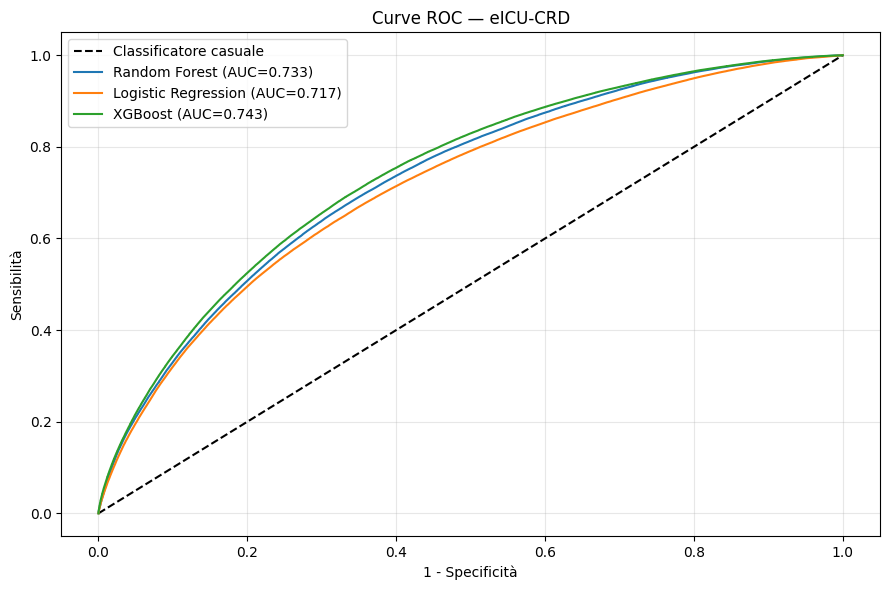

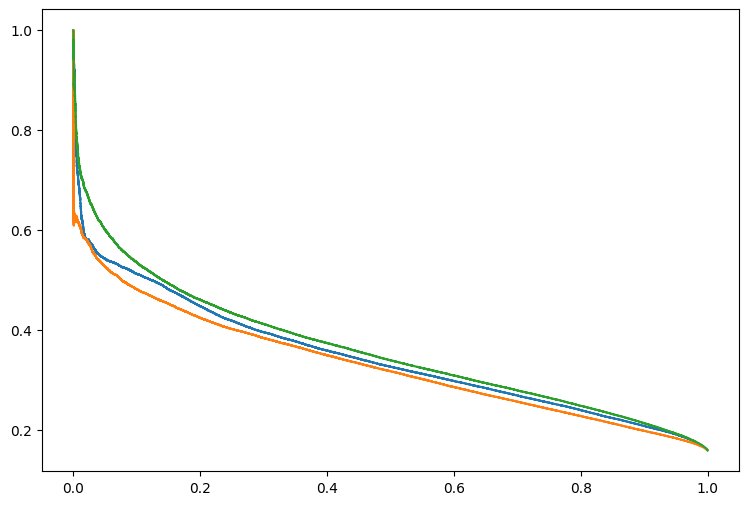

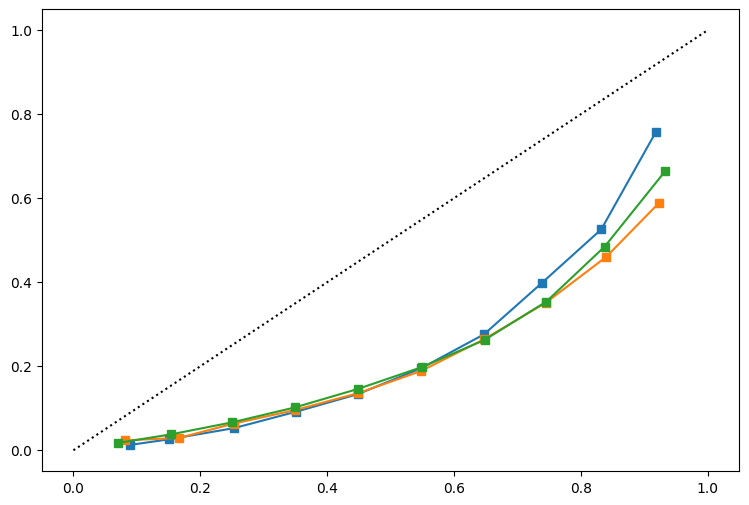

In [16]:
risultati = {}
prob_test_per_dca = {}

fig_roc, ax_roc = plt.subplots(figsize=(9,6))
ax_roc.plot([0,1],[0,1],"k--",label="Classificatore casuale")
fig_pr,  ax_pr  = plt.subplots(figsize=(9,6))
fig_cal, ax_cal = plt.subplots(figsize=(9,6))
ax_cal.plot([0,1],[0,1],"k:",label="Perfettamente calibrato")

for nome, modello in modelli.items():
    print(f"\nAddestrando {nome}...")
    if nome == "Logistic Regression":
        modello.fit(X_train_scaled, y_train)
        prob_val  = modello.predict_proba(X_val_scaled)[:,1]
        prob_test = modello.predict_proba(X_test_scaled)[:,1]
    else:
        modello.fit(X_train, y_train)
        prob_val  = modello.predict_proba(X_val)[:,1]
        prob_test = modello.predict_proba(X_test)[:,1]

    fpr_v, tpr_v, soglie_v = roc_curve(y_val, prob_val)
    soglia_ottimale = soglie_v[np.argmax(tpr_v - fpr_v)]
    # Metriche sul VALIDATION: servono solo a scegliere il modello (il test resta per la valutazione finale)
    auc_val   = roc_auc_score(y_val, prob_val)
    ap_val    = average_precision_score(y_val, prob_val)
    brier_val = brier_score_loss(y_val, prob_val)
    y_pred = (prob_test >= soglia_ottimale).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    auc   = roc_auc_score(y_test, prob_test)
    ap    = average_precision_score(y_test, prob_test)
    f1    = f1_score(y_test, y_pred, zero_division=0)
    prec  = precision_score(y_test, y_pred, zero_division=0)
    rec   = recall_score(y_test, y_pred, zero_division=0)
    spec  = tn/(tn+fp)
    brier = brier_score_loss(y_test, prob_test)

    risultati[nome] = {
        "AUC": round(auc,3), "AUPRC": round(ap,3), "F1": round(f1,3),
        "Sensibilità": round(rec,3), "Specificità": round(spec,3),
        "Precisione": round(prec,3), "Brier Score": round(brier,3),
        "Soglia Youden": round(soglia_ottimale,3),
        "AUC_val": round(auc_val,3), 
        "AUPRC_val": round(ap_val,3), 
        "Brier_val": round(brier_val,3),
    }
    prob_test_per_dca[nome] = prob_test
    print(f"  AUC={auc:.3f} | AUPRC={ap:.3f} | Brier={brier:.3f} | Sensib={rec:.3f}")

    fpr_t, tpr_t, _ = roc_curve(y_test, prob_test)
    ax_roc.plot(fpr_t, tpr_t, label=f"{nome} (AUC={auc:.3f})")
    prec_v, rec_v, _ = precision_recall_curve(y_test, prob_test)
    ax_pr.plot(rec_v, prec_v, label=f"{nome} (AUPRC={ap:.3f})")
    pt, pp = calibration_curve(y_test, prob_test, n_bins=10)
    ax_cal.plot(pp, pt, marker="s", label=f"{nome} (Brier={brier:.3f})")

for ax, fig, fname, titolo, xl, yl in [
    (ax_roc,fig_roc,"confronto_roc_eicu.png","Curve ROC — eICU-CRD","1 - Specificità","Sensibilità"),
    (ax_pr, fig_pr, "confronto_pr_eicu.png", "Curve PR — eICU-CRD", "Recall","Precisione"),
]:
    if ax is ax_pr:
        ax.axhline(y=y_test.mean(),color="k",linestyle="--",
                   label=f"Casuale (AP={y_test.mean():.3f})")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(titolo)
    ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig(f"outputs/{fname}",dpi=150); plt.show(); plt.close(fig)

ax_cal.set_xlabel("Probabilità predetta"); ax_cal.set_ylabel("Frequenza osservata")
ax_cal.set_title("Curve di Calibrazione — eICU-CRD")
ax_cal.legend(); ax_cal.grid(alpha=0.3); fig_cal.tight_layout()
fig_cal.savefig("outputs/confronto_calibrazione_eicu.png",dpi=150)
plt.show(); plt.close(fig_cal)


## 16. Decision Curve Analysis (Passo 2.3)

La DCA misura il **net benefit clinico** rispetto a due strategie banali:
- *Tratta tutti* — allerta sempre, indipendentemente dal rischio
- *Non trattare nessuno* — non allerta mai

Se la curva del modello supera entrambe nell'intervallo di soglie clinicamente
rilevanti (5%–40%), il sistema ha utilità clinica reale.

Il confronto dell'allarme del modello con le soglie cliniche del NEWS-2 (RCP 2017: ≥5 = risposta urgente,
≥7 = emergenza) è nella sezione sul tempo di anticipo, in fondo al notebook.

Riferimento: Vickers & Elkin, Medical Decision Making, 2006.

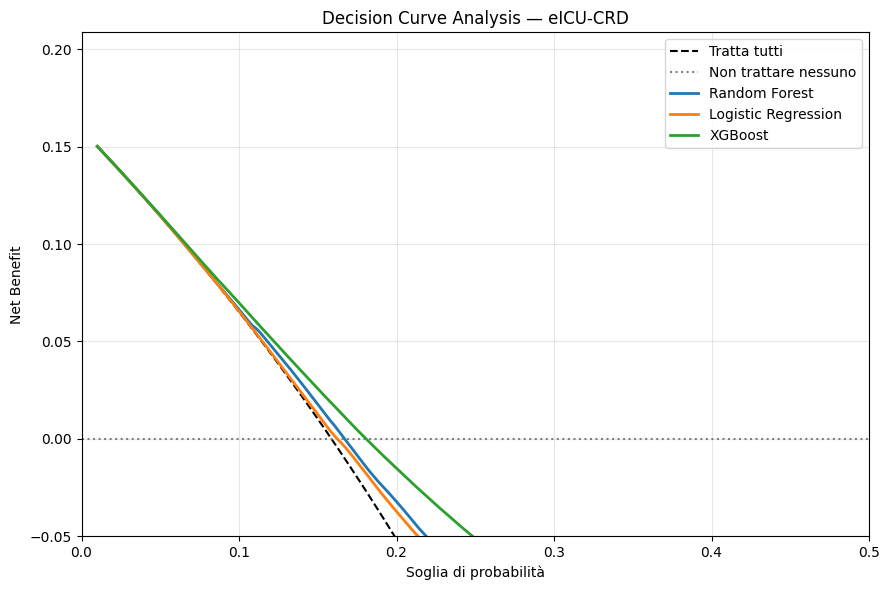

  DCA salvata in outputs/decision_curve_analysis_eicu.png


In [17]:
def decision_curve_analysis(y_true, prob_dict, thresholds=None, title="DCA"):
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.50, 200)
    n = len(y_true); prevalenza = y_true.mean()
    fig, ax = plt.subplots(figsize=(9,6))
    nb_tutti = [prevalenza-(1-prevalenza)*(t/(1-t)) for t in thresholds]
    ax.plot(thresholds, nb_tutti, "k--", label="Tratta tutti", linewidth=1.5)
    ax.axhline(0, color="gray", linestyle=":", label="Non trattare nessuno", linewidth=1.5)
    for nome, prob in prob_dict.items():
        nb_model = []
        for t in thresholds:
            y_pred = (prob >= t).astype(int)
            tp_v = ((y_pred==1)&(y_true==1)).sum()
            fp_v = ((y_pred==1)&(y_true==0)).sum()
            nb_model.append(tp_v/n - fp_v/n*(t/(1-t)))
        ax.plot(thresholds, nb_model, label=nome, linewidth=2)
    ax.set_xlabel("Soglia di probabilità"); ax.set_ylabel("Net Benefit")
    ax.set_title(title); ax.set_xlim(0,0.5); ax.set_ylim(-0.05, prevalenza+0.05)
    ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig("outputs/decision_curve_analysis_eicu.png", dpi=150)
    plt.show(); plt.close(fig)
    print("  DCA salvata in outputs/decision_curve_analysis_eicu.png")

decision_curve_analysis(y_test.values, prob_test_per_dca,
                        title="Decision Curve Analysis — eICU-CRD")


## 17. Tabella Riassuntiva e Selezione Modello Migliore (Passo 2.4)

Il modello si sceglie sulla **validazione**, mai sul test, con un punteggio composito:

**40% AUC + 30% AUPRC + 30% (1 − Brier)**

- AUC e AUPRC misurano quanto il modello distingue i pazienti a rischio da quelli stabili (l'AUPRC è più informativa con classi sbilanciate);
- il Brier misura quanto sono affidabili le probabilità, qui ancora **grezze** (prima della ricalibrazione).

Le metriche sul test compaiono nella tabella per completezza, ma non entrano nella scelta.

**Verifica (28/09/2026):** ricalibrando prima tutti e tre i modelli, oppure togliendo il Brier dal punteggio,
su eICU-CRD vince comunque XGBoost. La ricalibrazione fatta dopo non ha influito sulla scelta
(notebook `verifica_ricalibrazione_eicu.ipynb`).

In [18]:
import joblib

df_risultati = pd.DataFrame(risultati).T

# Punteggio composito: le tre dimensioni pesate
# Non basta l'AUC — in clinica la calibrazione pesa quanto la discriminazione
# Punteggio composito calcolato sul VALIDATION: il test resta solo per la valutazione finale
df_risultati["punteggio_composito"] = (
    df_risultati["AUC_val"].astype(float) * 0.40 +
    df_risultati["AUPRC_val"].astype(float) * 0.30 +
    (1 - df_risultati["Brier_val"].astype(float)) * 0.30
)
df_risultati = df_risultati.sort_values("punteggio_composito", ascending=False)

print("\n" + "="*75)
print("CONFRONTO MODELLI — eICU-CRD")
print("="*75)
print("Criteri di selezione:")
print("  40% — AUC      (discriminazione)")
print("  30% — AUPRC    (performance su classi sbilanciate)")
print("  30% — 1-Brier  (calibrazione — affidabilità clinica)")
print("="*75)
print(df_risultati.to_string())

migliore = df_risultati.index[0]
print(f"\n✓ Modello migliore: {migliore}")
print(f"  AUC={df_risultati.loc[migliore,'AUC']} | "
      f"AUPRC={df_risultati.loc[migliore,'AUPRC']} | "
      f"Brier={df_risultati.loc[migliore,'Brier Score']} | "
      f"Composito={df_risultati.loc[migliore,'punteggio_composito']:.4f}")

joblib.dump(modelli[migliore], "models/modello_news2_eicu.pkl")
joblib.dump(scaler, "models/scaler_eicu.pkl")
print("✓ Modello e scaler salvati in models/")



CONFRONTO MODELLI — eICU-CRD
Criteri di selezione:
  40% — AUC      (discriminazione)
  30% — AUPRC    (performance su classi sbilanciate)
  30% — 1-Brier  (calibrazione — affidabilità clinica)
                       AUC  AUPRC     F1  Sensibilità  Specificità  Precisione  Brier Score  Soglia Youden  AUC_val  AUPRC_val  Brier_val  punteggio_composito
XGBoost              0.743  0.360  0.403        0.665        0.691       0.289        0.199          0.501    0.754      0.382      0.200               0.6562
Random Forest        0.733  0.345  0.393        0.665        0.675       0.279        0.207          0.505    0.746      0.370      0.207               0.6473
Logistic Regression  0.717  0.330  0.384        0.634        0.685       0.275        0.212          0.506    0.731      0.348      0.212               0.6332

✓ Modello migliore: XGBoost
  AUC=0.743 | AUPRC=0.36 | Brier=0.199 | Composito=0.6562
✓ Modello e scaler salvati in models/


### Confronto con il NEWS-2 usato da solo
Il NEWS-2 è un punteggio: si usa direttamente per ordinare i pazienti (più è alto, più il rischio è alto),
senza addestrare nulla. Calcolando l'AUC sugli **stessi pazienti del test** si confronta il modello con ciò
che si usa già in clinica: è il primo obiettivo della tesi.

Per completezza si confrontano anche altri riferimenti semplici: la media e il massimo del NEWS-2 nelle
ultime 6 ore e il Delta-NEWS a 6 ore usato da solo.

In [19]:
# =============================================================================
# CONFRONTO CON IL NEWS-2 USATO DA SOLO
# =============================================================================
from sklearn.metrics import roc_auc_score

X_test_modello = X_test_scaled if migliore == "Logistic Regression" else X_test
prob_modello = modelli[migliore].predict_proba(X_test_modello)[:, 1]

confronto = {
    "NEWS-2 istantaneo (pratica clinica)": X_test["news2"],
    "NEWS-2 media ultime 6h":              X_test["news2_media_6h"],
    "NEWS-2 massimo ultime 6h":            X_test["news2_max_6h"],
    "Delta-NEWS 6h da solo":               X_test["delta_news_6h"],
    f"Modello completo ({migliore})":      prob_modello,
}
print("=" * 60)
print("AUC sul test — eICU-CRD")
print("=" * 60)
for nome, punteggio in confronto.items():
    print(f"  {nome:38s} {roc_auc_score(y_test, punteggio):.3f}")

AUC sul test — eICU-CRD


  NEWS-2 istantaneo (pratica clinica)    0.650


  NEWS-2 media ultime 6h                 0.668


  NEWS-2 massimo ultime 6h               0.653


  Delta-NEWS 6h da solo                  0.509


  Modello completo (XGBoost)             0.743


## 18. Explainable AI — SHAP (Passo 2.5)
Il beeswarm plot mostra quali feature influenzano di più la predizione e in quale direzione.
Permette di verificare quanto pesano nelle decisioni del modello il NEWS-2, il Delta-NEWS e gli altri parametri.

Nota di lettura: nel lavoro il Delta-NEWS **non** è risultato tra le variabili più influenti (anche usato da solo
ha un'AUC vicina al caso), quindi non va presentato come il fattore principale del modello.


Calcolo valori SHAP...


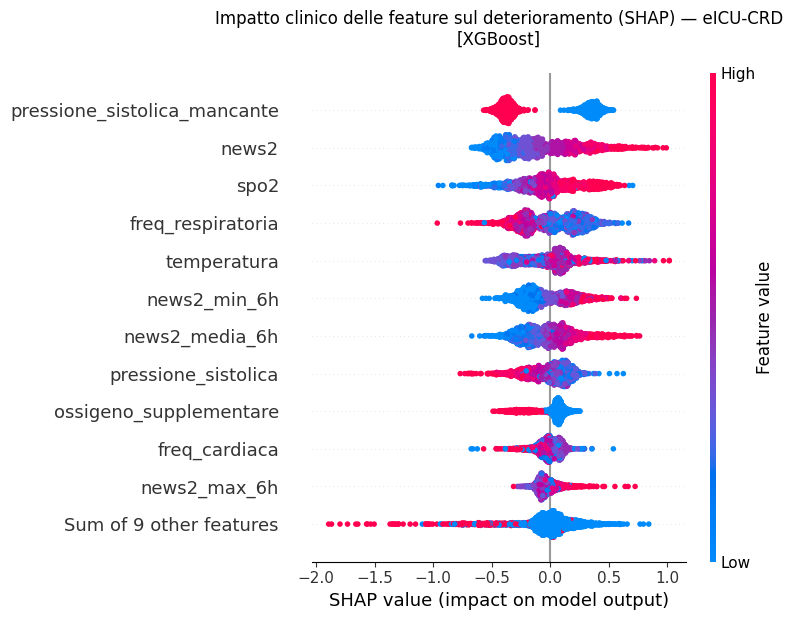

✓ SHAP salvato in outputs/shap_beeswarm_eicu.png


In [20]:
import shap

print("Calcolo valori SHAP...")

esploratore = shap.Explainer(modelli[migliore])
X_campione  = X_test.sample(min(2000, len(X_test)), random_state=42)
valori_shap = esploratore(X_campione)

# Gestisce sia modelli con output binario (3D) che altri (2D)
if len(valori_shap.shape) == 3:
    shap_da_plottare = valori_shap[:, :, 1]  # classe positiva
else:
    shap_da_plottare = valori_shap            # già 2D

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_da_plottare, max_display=12, show=False)
plt.title(f"Impatto clinico delle feature sul deterioramento (SHAP) — eICU-CRD\n[{migliore}]", pad=20)
plt.tight_layout()
plt.savefig("outputs/shap_beeswarm_eicu.png", dpi=150)
plt.show()
print("✓ SHAP salvato in outputs/shap_beeswarm_eicu.png")

## 19. Intervallo di confidenza al 95% — bootstrap per paziente (Passo 2.6)
Il test è un gruppo di pazienti scelto a caso: con un altro gruppo simile l'AUC sarebbe un po' diversa.
L'intervallo di confidenza al 95% dice **di quanto**, cioè quanto è stabile il risultato.

Si calcola **alla fine, solo sul modello già scelto** e solo sui pazienti del test: non serve a scegliere il
modello (la scelta è già stata fatta sulla validazione).

**Procedimento (bootstrap):**
1. dai pazienti del test se ne estrae a caso lo stesso numero, **con reinserimento** (lo stesso paziente può uscire più volte, un altro nessuna);
2. si ricalcola l'AUC su questo nuovo gruppo;
3. si ripete 1.000 volte: l'intervallo al 95% va dal 2,5° al 97,5° percentile delle 1.000 AUC.

Non si aggiungono pazienti nuovi, non si modificano i dati e non si riaddestra il modello: cambia solo quali
pazienti contano.

**Ricampionamento per paziente.** Il test set contiene molte righe per ogni paziente (una ogni 10 minuti), fortemente correlate tra loro. Il bootstrap quindi ricampiona i **pazienti** (con reinserimento) e per ciascuno tiene tutte le sue righe: è il cosiddetto *cluster bootstrap*. Ricampionare le singole righe tratterebbe come indipendenti misure che non lo sono e produrrebbe intervalli di confidenza artificialmente stretti (circa ±0,001 invece di circa ±0,01).

**Come si legge:** un intervallo stretto vuol dire che il risultato non dipende da quali pazienti sono capitati
nel test. Se gli intervalli di due database si sovrappongono quasi del tutto, la differenza tra le due AUC non
va considerata reale. L'intervallo non dice se il modello funziona in altri ospedali: questo lo mostra il
confronto tra i tre database.

In [21]:
from sklearn.utils import resample

print("Calcolo 95% CI via bootstrapping (1000 iterazioni)...")

# Usa il modello migliore selezionato dal punteggio composito
if migliore == "Logistic Regression":
    prob_migliore = modelli[migliore].predict_proba(X_test_scaled)[:,1]
else:
    prob_migliore = modelli[migliore].predict_proba(X_test)[:,1]

# Bootstrap PER PAZIENTE (cluster bootstrap): si ricampionano i pazienti del test set con
# reinserimento e si tengono tutte le loro righe. Le righe dello stesso paziente sono molto simili
# tra loro (una ogni 10 minuti): ricampionare le singole righe, come si faceva prima, trattava come
# indipendenti misure che non lo sono e dava intervalli falsamente stretti (circa +-0,001).
# Un paziente estratto k volte pesa k volte: lo si ottiene con sample_weight, senza copiare le righe.
id_test = np.asarray(df_test["uniquepid"])                             # uniquepid (persona) di ogni riga del test set
codici_paz, pazienti_test = pd.factorize(id_test)           # ogni uniquepid (persona) -> un numero 0..N-1
n_paz = len(pazienti_test)
y_boot = np.asarray(y_test)
rng_boot = np.random.default_rng(42)

punteggi_auc_bootstrap = []
for i in range(1000):
    estratti = rng_boot.integers(0, n_paz, n_paz)                 # N pazienti estratti con reinserimento
    peso = np.bincount(estratti, minlength=n_paz)[codici_paz]      # quante volte e' stato estratto il paziente di ogni riga
    tenute = peso > 0
    if len(np.unique(y_boot[tenute])) < 2:
        continue
    punteggi_auc_bootstrap.append(
        roc_auc_score(y_boot[tenute], prob_migliore[tenute], sample_weight=peso[tenute]))

limite_inferiore = np.percentile(punteggi_auc_bootstrap, 2.5)
limite_superiore = np.percentile(punteggi_auc_bootstrap, 97.5)
auc_originale = roc_auc_score(y_boot, prob_migliore)

print("="*60)
print(f"RISULTATI STATISTICI - {migliore} (Test Set) — eICU-CRD")
print("="*60)
print(f"Pazienti nel test set: {n_paz:,} | righe: {len(y_boot):,}")
print(f"AUC puntuale: {auc_originale:.3f}")
print(f"95% CI (bootstrap per paziente, 1000 iterazioni): [{limite_inferiore:.3f} - {limite_superiore:.3f}]")
print("="*60)
print()
print("✓ eICU-CRD completato.")


Calcolo 95% CI via bootstrapping (1000 iterazioni)...


RISULTATI STATISTICI - XGBoost (Test Set) — eICU-CRD
Pazienti nel test set: 3,810 | righe: 1,600,915
AUC puntuale: 0.743
95% CI (bootstrap per paziente, 1000 iterazioni): [0.729 - 0.760]

✓ eICU-CRD completato.


### Ricalibrazione delle probabilità (isotonic regression)
Le curve di calibrazione mostrano che il modello **sovrastima** il rischio: la probabilità predetta è più alta
della frequenza osservata su quasi tutto l'intervallo (Brier peggiore del Brier banale della sola prevalenza).
È l'effetto atteso di `class_weight='balanced'` / `scale_pos_weight`: in addestramento i casi di
deterioramento, che sono pochi, pesano di più, e il modello impara come se fossero circa la metà.

Correggiamo con una **regressione isotonica**: una trasformazione monotona appresa SOLO sul validation set
(mai sul test, per non introdurre data leakage) che mappa la probabilità grezza del modello nella probabilità
calibrata. L'AUC non cambia per costruzione (la trasformazione è monotona, non altera l'ordinamento dei
pazienti per rischio): cambia solo l'affidabilità del numero, utile per un'eventuale soglia clinica basata sul
rischio assoluto e non solo sul ranking.

La ricalibrazione si applica **dopo** la scelta del modello e solo al modello scelto. È stato verificato che,
ricalibrando prima tutti e tre i modelli, la scelta non cambia.

RICALIBRAZIONE (isotonic, adattata sul validation) — XGBoost
Brier PRIMA della ricalibrazione : 0.1992
Brier DOPO  la ricalibrazione    : 0.1188
AUC   PRIMA della ricalibrazione : 0.7431
AUC   DOPO  la ricalibrazione    : 0.7431  (invariata per costruzione, a meno di pareggi)


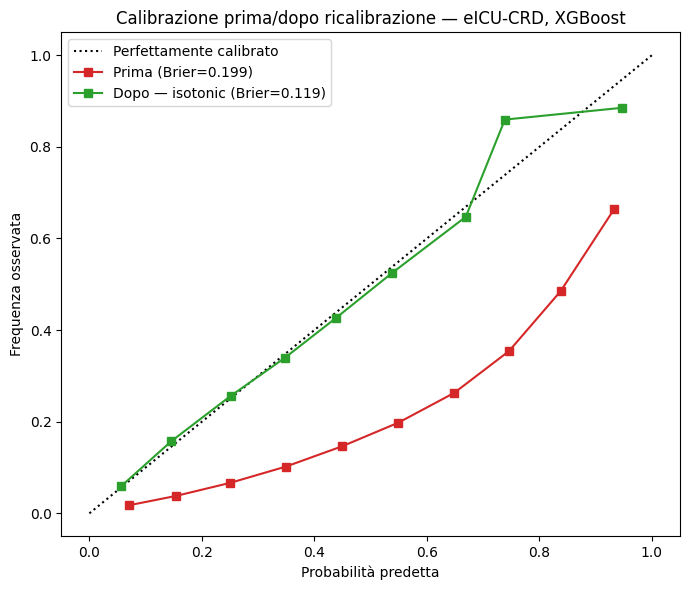


OK - Regressione isotonica salvata in models/isotonic_eicu.pkl
Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])


In [22]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

modello_sel = modelli[migliore]
X_val_per_cal  = X_val_scaled  if migliore == 'Logistic Regression' else X_val
X_test_per_cal = X_test_scaled if migliore == 'Logistic Regression' else X_test

prob_val_migliore  = modello_sel.predict_proba(X_val_per_cal)[:, 1]
prob_test_migliore = modello_sel.predict_proba(X_test_per_cal)[:, 1]

calibratore = IsotonicRegression(out_of_bounds="clip")
calibratore.fit(prob_val_migliore, y_val)   # la mappa si impara SOLO sul validation, mai sul test

prob_test_calibrata = calibratore.predict(prob_test_migliore)

brier_prima = brier_score_loss(y_test, prob_test_migliore)
brier_dopo  = brier_score_loss(y_test, prob_test_calibrata)
auc_prima   = roc_auc_score(y_test, prob_test_migliore)
auc_dopo    = roc_auc_score(y_test, prob_test_calibrata)

print("=" * 60)
print(f"RICALIBRAZIONE (isotonic, adattata sul validation) — {migliore}")
print("=" * 60)
print(f"Brier PRIMA della ricalibrazione : {brier_prima:.4f}")
print(f"Brier DOPO  la ricalibrazione    : {brier_dopo:.4f}")
print(f"AUC   PRIMA della ricalibrazione : {auc_prima:.4f}")
print(f"AUC   DOPO  la ricalibrazione    : {auc_dopo:.4f}  (invariata per costruzione, a meno di pareggi)")
print("=" * 60)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k:", label="Perfettamente calibrato")
pt0, pp0 = calibration_curve(y_test, prob_test_migliore, n_bins=10)
pt1, pp1 = calibration_curve(y_test, prob_test_calibrata, n_bins=10)
ax.plot(pp0, pt0, "s-", color="tab:red", label=f"Prima (Brier={brier_prima:.3f})")
ax.plot(pp1, pt1, "s-", color="tab:green", label=f"Dopo — isotonic (Brier={brier_dopo:.3f})")
ax.set_xlabel("Probabilità predetta"); ax.set_ylabel("Frequenza osservata")
ax.set_title(f"Calibrazione prima/dopo ricalibrazione — eICU-CRD, {migliore}")
ax.legend(); plt.tight_layout()
plt.savefig("outputs/calibrazione_isotonic_eicu.png", dpi=150)
plt.show()

joblib.dump(calibratore, "models/isotonic_eicu.pkl")
print()
print("OK - Regressione isotonica salvata in models/isotonic_eicu.pkl")
print("Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])")


### Decision Curve Analysis sulle probabilità calibrate
La DCA confronta il **beneficio netto** del modello con due strategie banali: dare l'allarme a tutti o a nessuno
(Vickers & Elkin, *Medical Decision Making*, 2006). Nella DCA la soglia è un rischio assoluto
("intervengo sopra il 20%"), quindi servono probabilità calibrate: si usa il modello scelto dopo la
ricalibrazione isotonica.

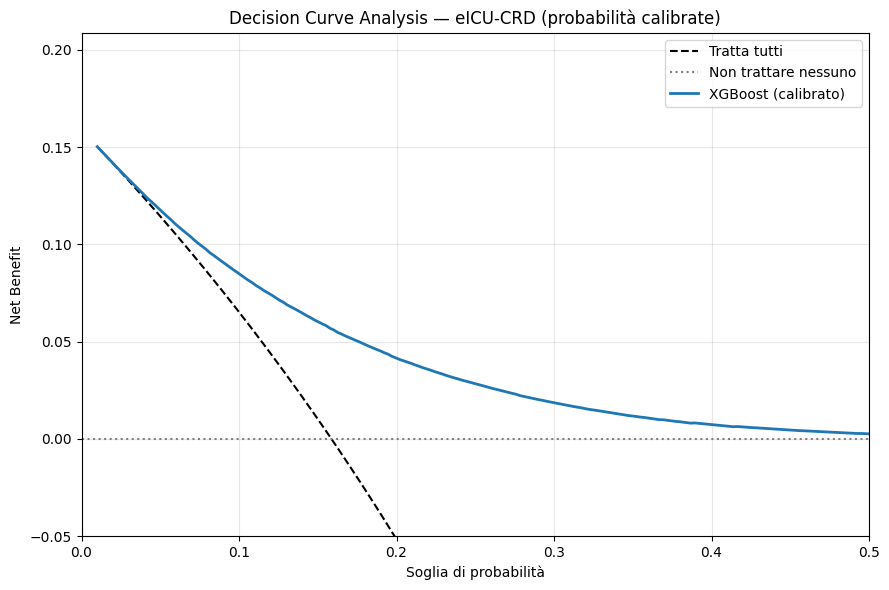

  DCA salvata in outputs/decision_curve_analysis_eicu.png


In [23]:
# =============================================================================
# DECISION CURVE ANALYSIS SULLE PROBABILITÀ CALIBRATE
# Nella DCA la soglia è un rischio vero ("intervengo sopra il 20%"), quindi
# servono probabilità calibrate. Si usa il modello migliore dopo la
# ricalibrazione isotonica (adattata solo sul validation).
# =============================================================================
decision_curve_analysis(
    y_test.values,
    {f"{migliore} (calibrato)": prob_test_calibrata},
    title="Decision Curve Analysis — eICU-CRD (probabilità calibrate)"
)

### Tempo di anticipo degli allarmi
L'AUC valuta ogni blocco di 10 minuti. Un medico però chiede: **quanto prima mi avvisa il sistema, per ogni evento?**
Per ogni evento dei pazienti del test (morte, inizio di un vasopressore, intubazione) si guardano le **24 ore precedenti**,
la stessa finestra dell'etichetta:
- l'evento è **intercettato** se in quelle 24 ore il modello supera almeno una volta la soglia di allarme (Youden, scelta sulla validazione);
- l'**anticipo** è il tempo tra il **primo** allarme della finestra e l'evento (massimo 24 ore);
- gli eventi senza nessuna osservazione nelle 24 ore precedenti (per esempio all'inizio del ricovero) non sono valutabili e sono contati a parte.

Si usa il modello già scelto, sulle probabilità grezze e con la stessa soglia: nessun nuovo addestramento, nessun risultato precedente cambia.
La misura "eventi segnalati con almeno 2 ore di anticipo" è confrontabile con Hyland et al., Nature Medicine 2020.

Per leggere correttamente questi numeri servono due confronti, calcolati nella stessa cella:
- **falsi allarmi**: nei ricoveri senza nessun evento, quanti ricevono comunque almeno un allarme e per quanta parte del tempo;
- **NEWS-2 come riferimento**: la stessa misura con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza).


In [24]:
# =============================================================================
# TEMPO DI ANTICIPO DEGLI ALLARMI (analisi aggiunta, non cambia i risultati precedenti)
# =============================================================================
from sklearn.metrics import roc_curve

def tempo_di_anticipo(righe, eventi, chiavi, soglia, finestra_ore=24):
    # righe: chiavi + "t" (ore) + "prob"; eventi: chiavi + "t_evento" (ore) + "tipo_evento"
    eventi = eventi.drop_duplicates(chiavi + ["t_evento", "tipo_evento"]).reset_index(drop=True)
    eventi["id_evento"] = eventi.index
    m = eventi.merge(righe, on=chiavi, how="inner")
    m = m[(m["t"] < m["t_evento"]) & (m["t"] >= m["t_evento"] - finestra_ore)]   # solo le 24 ore PRIMA dell'evento
    per_evento = m.groupby("id_evento").agg(tipo=("tipo_evento", "first"), t_evento=("t_evento", "first"))
    per_evento["t_primo_allarme"] = m[m["prob"] >= soglia].groupby("id_evento")["t"].min()
    per_evento["anticipo_ore"] = per_evento["t_evento"] - per_evento["t_primo_allarme"]   # NaN = nessun allarme = evento mancato
    return per_evento, len(eventi)

def riassunto_anticipo(per_evento, n_eventi, nome_db):
    intercettato = per_evento["anticipo_ore"].notna()
    almeno_2h = per_evento["anticipo_ore"] >= 2
    anticipi = per_evento.loc[intercettato, "anticipo_ore"]
    print("=" * 70)
    print(f"TEMPO DI ANTICIPO DEGLI ALLARMI — {nome_db}")
    print("=" * 70)
    print(f"Eventi nei pazienti del test:                        {n_eventi:,}")
    print(f"Valutabili (almeno un'osservazione nelle 24 h prima): {len(per_evento):,}")
    print(f"Intercettati (almeno un allarme nelle 24 h prima):    {int(intercettato.sum()):,} ({100 * intercettato.mean():.1f}%)")
    print(f"Segnalati con almeno 2 ore di anticipo:               {int(almeno_2h.sum()):,} ({100 * almeno_2h.mean():.1f}%)")
    print(f"Anticipo del primo allarme (eventi intercettati): mediana {anticipi.median():.1f} ore, "
          f"IQR {anticipi.quantile(0.25):.1f}-{anticipi.quantile(0.75):.1f} ore")
    per_tipo = (per_evento.assign(intercettato=intercettato, almeno_2h=almeno_2h)
                .groupby("tipo")
                .agg(eventi=("intercettato", "size"),
                     intercettati_pct=("intercettato", "mean"),
                     almeno_2h_pct=("almeno_2h", "mean"),
                     anticipo_mediano_ore=("anticipo_ore", "median")))
    per_tipo[["intercettati_pct", "almeno_2h_pct"]] = (100 * per_tipo[["intercettati_pct", "almeno_2h_pct"]]).round(1)
    per_tipo["anticipo_mediano_ore"] = per_tipo["anticipo_mediano_ore"].round(1)
    print()
    print("Per tipo di evento:")
    print(per_tipo.to_string())
    print("=" * 70)

def carico_allarmi(righe, eventi, chiavi, soglia, nome):
    # Falsi allarmi: nei ricoveri SENZA nessun evento, quanto spesso il sistema dà comunque l'allarme?
    con_eventi = eventi[chiavi].drop_duplicates()
    senza = righe.merge(con_eventi.assign(_ev=1), on=chiavi, how="left")
    senza = senza[senza["_ev"].isna()]
    in_allarme = senza["prob"] >= soglia
    ricoveri_con_allarme = in_allarme.groupby([senza[k] for k in chiavi]).any()
    print(f"  {nome}: ricoveri senza eventi {ricoveri_con_allarme.size:,}; "
          f"con almeno un allarme {100 * ricoveri_con_allarme.mean():.1f}%; "
          f"tempo in allarme {100 * in_allarme.mean():.1f}% dei blocchi")

def confronto_con_news2(righe, eventi, chiavi, soglia_modello):
    # Stessa misura con il modello e con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza)
    print()
    print("CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)")
    righe_news = righe.assign(prob=righe["news2"])
    riga = []
    for nome, r, s in [("Modello", righe, soglia_modello), ("NEWS-2 >= 5", righe_news, 5), ("NEWS-2 >= 7", righe_news, 7)]:
        pe, _ = tempo_di_anticipo(r[chiavi + ["t", "prob"]], eventi, chiavi, s)
        intercettato = pe["anticipo_ore"].notna()
        riga.append({"allarme": nome,
                     "intercettati_%": round(100 * intercettato.mean(), 1),
                     "almeno_2h_%": round(100 * (pe["anticipo_ore"] >= 2).mean(), 1),
                     "anticipo_mediano_ore": round(pe.loc[intercettato, "anticipo_ore"].median(), 1)})
    print(pd.DataFrame(riga).to_string(index=False))
    print()
    print("FALSI ALLARMI (ricoveri del test senza nessun evento)")
    carico_allarmi(righe, eventi, chiavi, soglia_modello, "Modello    ")
    carico_allarmi(righe_news, eventi, chiavi, 5, "NEWS-2 >= 5")
    carico_allarmi(righe_news, eventi, chiavi, 7, "NEWS-2 >= 7")

def ore(tempi):
    # istanti di tempo -> ore (numero), per poter fare differenze semplici
    return pd.to_datetime(tempi).astype("int64") / 3.6e12

# Soglia di allarme del modello migliore, ricalcolata sulla validazione come nel ciclo di addestramento
fpr_v, tpr_v, soglie_v = roc_curve(y_val, prob_val_migliore)
soglia_allarme = soglie_v[np.argmax(tpr_v - fpr_v)]
print(f"Soglia di allarme ({migliore}): {soglia_allarme:.3f}")

# Orari delle righe del test (offset in minuti -> ore): df_test conserva l'indice di df
righe_test = df.loc[df_test.index, ["patientunitstayid", "observationoffset"]].reset_index(drop=True)
assert (righe_test["patientunitstayid"].values == df_test["patientunitstayid"].values).all(), "ordine delle righe diverso dal test"
righe_test["t"] = righe_test["observationoffset"] / 60
righe_test["prob"] = prob_test_migliore
righe_test["news2"] = X_test["news2"].values

ricoveri_test = set(df_test["patientunitstayid"])
eventi_test = tutti_eventi.dropna(subset=["evento_offset"])
eventi_test = eventi_test[eventi_test["patientunitstayid"].isin(ricoveri_test)].copy()
eventi_test["t_evento"] = eventi_test["evento_offset"].astype(float) / 60

per_evento, n_eventi = tempo_di_anticipo(righe_test[["patientunitstayid", "t", "prob"]],
                                         eventi_test[["patientunitstayid", "t_evento", "tipo_evento"]],
                                         ["patientunitstayid"], soglia_allarme)
riassunto_anticipo(per_evento, n_eventi, "eICU-CRD")
confronto_con_news2(righe_test, eventi_test[["patientunitstayid", "t_evento", "tipo_evento"]], ["patientunitstayid"], soglia_allarme)


Soglia di allarme (XGBoost): 0.501


TEMPO DI ANTICIPO DEGLI ALLARMI — eICU-CRD
Eventi nei pazienti del test:                        3,640
Valutabili (almeno un'osservazione nelle 24 h prima): 3,558
Intercettati (almeno un allarme nelle 24 h prima):    3,413 (95.9%)
Segnalati con almeno 2 ore di anticipo:               2,852 (80.2%)
Anticipo del primo allarme (eventi intercettati): mediana 22.7 ore, IQR 5.5-23.9 ore

Per tipo di evento:
              eventi  intercettati_pct  almeno_2h_pct  anticipo_mediano_ore
tipo                                                                       
intubazione     2186              96.1           77.4                  22.6
morte_icu        224              99.1           94.6                  23.8
vasopressore    1148              95.0           82.6                  22.5

CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)


    allarme  intercettati_%  almeno_2h_%  anticipo_mediano_ore
    Modello            95.9         80.2                  22.7
NEWS-2 >= 5            84.1         72.1                  21.2
NEWS-2 >= 7            68.5         59.9                  18.8

FALSI ALLARMI (ricoveri del test senza nessun evento)


  Modello    : ricoveri senza eventi 2,804; con almeno un allarme 86.9%; tempo in allarme 20.3% dei blocchi


  NEWS-2 >= 5: ricoveri senza eventi 2,804; con almeno un allarme 77.7%; tempo in allarme 24.0% dei blocchi


  NEWS-2 >= 7: ricoveri senza eventi 2,804; con almeno un allarme 50.7%; tempo in allarme 8.4% dei blocchi


### Consensus dei tre modelli (ensemble)
Proposta del professore (30 settembre 2026): invece di scegliere un solo modello, si mettono insieme le risposte dei tre
(regressione logistica, Random Forest, XGBoost) per arrivare a una risposta sola. Nessun riaddestramento.
- Ogni modello viene prima ricalibrato (isotonica, sul validation): le tre probabilità finiscono sulla stessa scala
- **Media**: media semplice delle tre probabilità (soft voting)
- **Media pesata**: pesi scelti sul validation con lo stesso punteggio composito usato per scegliere il modello
- **Voto a maggioranza**: allarme se almeno 2 modelli su 3 superano la propria soglia di Youden
- Confronto sul test con il modello scelto, ricalibrato allo stesso modo; differenza di AUC con bootstrap per paziente appaiato

In [25]:
# =============================================================================
# CONSENSUS (ENSEMBLE) DEI TRE MODELLI — eICU-CRD
# =============================================================================
# Invece di tenere un solo modello, si combinano le risposte dei tre gia' addestrati
# (nessun riaddestramento). Ogni modello viene prima ricalibrato con la regressione isotonica
# sul validation, cosi' le tre probabilita' sono sulla stessa scala; poi:
#   1) MEDIA       = media semplice delle tre probabilita' calibrate (soft voting)
#   2) MEDIA PESATA = pesi scelti sul validation con il punteggio composito (stesso criterio
#                    usato per scegliere il modello); il test resta cieco
#   3) VOTO        = numero di modelli in allarme (0-3), ciascuno con la sua soglia di Youden
#                    scelta sul validation; allarme del consensus = almeno 2 su 3 (maggioranza)
# Il confronto sul test e' con il modello scelto oggi; la differenza di AUC ha un intervallo
# di confidenza con bootstrap per paziente APPAIATO (stessi pazienti estratti per i due modelli).
import itertools
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, confusion_matrix

COLONNA_ID = "uniquepid"   # unita' del bootstrap: paziente (persona in eICU-CRD)

def _prob(nome, X, X_sc):
    return modelli[nome].predict_proba(X_sc if nome == "Logistic Regression" else X)[:, 1]

nomi = list(modelli.keys())
cal_val, cal_test, soglie = {}, {}, {}
for nome in nomi:
    pv, pt = _prob(nome, X_val, X_val_scaled), _prob(nome, X_test, X_test_scaled)
    iso = IsotonicRegression(out_of_bounds="clip").fit(pv, y_val)   # mappa imparata solo sul validation
    cal_val[nome], cal_test[nome] = iso.predict(pv), iso.predict(pt)
    fpr, tpr, thr = roc_curve(y_val, pv)
    soglie[nome] = (thr[np.argmax(tpr - fpr)], pv, pt)              # soglia di Youden sul validation (prob. grezze)

def _pesa(w, probs):   # somma pesata; clip per gli arrotondamenti (1.0000000000000002)
    return np.clip(sum(w_i * probs[n] for w_i, n in zip(w, nomi)), 0, 1)

def _composito(y, p):
    return 0.40 * roc_auc_score(y, p) + 0.30 * average_precision_score(y, p) + 0.30 * (1 - brier_score_loss(y, p))

# 1) Media semplice
media_val  = np.mean([cal_val[n] for n in nomi], axis=0)
media_test = np.mean([cal_test[n] for n in nomi], axis=0)

# 2) Media pesata: griglia di pesi a passi di 0,1 che sommano a 1, scelta sul validation
griglia = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(nomi)) if abs(sum(w) - 1) < 1e-9]
punteggi = [(_composito(y_val, _pesa(w, cal_val)), w) for w in griglia]
_, pesi = max(punteggi, key=lambda t: t[0])
pesata_test = _pesa(pesi, cal_test)

# 3) Voto: quanti modelli sono in allarme
voti_test = sum((soglie[n][2] >= soglie[n][0]).astype(int) for n in nomi)

# Modello scelto oggi, calibrato allo stesso modo (riferimento del confronto)
rif_test = cal_test[migliore]

def _riga(nome_riga, p, allarme=None):
    if allarme is None:   # soglia di Youden scelta sul validation per le probabilita' continue
        p_val = {"Modello scelto": cal_val[migliore], "Media": media_val,
                 "Media pesata": _pesa(pesi, cal_val)}[nome_riga.split(" (")[0]]
        fpr, tpr, thr = roc_curve(y_val, p_val)
        allarme = (p >= thr[np.argmax(tpr - fpr)]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, allarme).ravel()
    return {"AUC": roc_auc_score(y_test, p), "AUPRC": average_precision_score(y_test, p),
            "Brier": brier_score_loss(y_test, p) if p.max() <= 1 else np.nan,
            "Sensibilita": tp / (tp + fn), "Specificita": tn / (tn + fp)}

tabella = pd.DataFrame({
    f"Modello scelto ({migliore})": _riga("Modello scelto", rif_test),
    "Media": _riga("Media", media_test),
    "Media pesata": _riga("Media pesata", pesata_test),
    "Voto a maggioranza (>=2 su 3)": _riga("Voto", voti_test.astype(float), allarme=(voti_test >= 2).astype(int)),
}).T

# Bootstrap per paziente appaiato: differenza di AUC (consensus - modello scelto)
id_righe = np.asarray(df_test[COLONNA_ID])
codici, unici = pd.factorize(id_righe)
y_arr = np.asarray(y_test)
rng_c = np.random.default_rng(42)
diff_media, diff_pesata = [], []
for _ in range(1000):
    peso = np.bincount(rng_c.integers(0, len(unici), len(unici)), minlength=len(unici))[codici]
    k = peso > 0
    if len(np.unique(y_arr[k])) < 2:
        continue
    a_rif = roc_auc_score(y_arr[k], rif_test[k], sample_weight=peso[k])
    diff_media.append(roc_auc_score(y_arr[k], media_test[k], sample_weight=peso[k]) - a_rif)
    diff_pesata.append(roc_auc_score(y_arr[k], pesata_test[k], sample_weight=peso[k]) - a_rif)

print("=" * 78)
print("CONSENSUS DEI TRE MODELLI — eICU-CRD (test set, probabilita' ricalibrate sul validation)")
print("=" * 78)
print("Pesi della media pesata (scelti sul validation): " + ", ".join(f"{n} {w:.1f}" for n, w in zip(nomi, pesi)))
print(tabella.round(3).to_string())
print("-" * 78)
for nome_d, d in [("Media", diff_media), ("Media pesata", diff_pesata)]:
    print(f"Differenza di AUC {nome_d} - modello scelto: {np.mean(d):+.4f}  "
          f"95% CI [{np.percentile(d, 2.5):+.4f} ; {np.percentile(d, 97.5):+.4f}]  (bootstrap per paziente, appaiato)")
print("Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.")
tabella.to_csv("outputs/consensus_eicu.csv")
print("Tabella salvata in outputs/consensus_eicu.csv")


CONSENSUS DEI TRE MODELLI — eICU-CRD (test set, probabilita' ricalibrate sul validation)
Pesi della media pesata (scelti sul validation): Random Forest 0.2, Logistic Regression 0.1, XGBoost 0.7
                                 AUC  AUPRC  Brier  Sensibilita  Specificita
Modello scelto (XGBoost)       0.743  0.357  0.119        0.665        0.691
Media                          0.740  0.356  0.119        0.664        0.686
Media pesata                   0.744  0.362  0.119        0.662        0.695
Voto a maggioranza (>=2 su 3)  0.698  0.265    NaN        0.664        0.682
------------------------------------------------------------------------------
Differenza di AUC Media - modello scelto: -0.0034  95% CI [-0.0071 ; -0.0001]  (bootstrap per paziente, appaiato)
Differenza di AUC Media pesata - modello scelto: +0.0010  95% CI [-0.0006 ; +0.0025]  (bootstrap per paziente, appaiato)
Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.
Tabella salvata in out